# Bài tập 1: Ảnh hưởng của learning rate và vị trí bắt đầu

Trong bài tập này, bạn sẽ quan sát cách learning rate và vị trí bắt đầu ảnh hưởng đến Gradient Descent.

Chạy các thí nghiệm để quan sát và so sánh, sau đó chỉ điền đáp án vào các câu hỏi tổng hợp ở cuối mỗi phần 1.1 và 1.2. Double-click ô Markdown để sửa câu trả lời; nhấn Shift+Enter để hiển thị lại.

Đọc kết quả được in bên trên biểu đồ và lưu ý giới hạn số bước, cũng như miền hiển thị của từng thí nghiệm.


In [1]:
from utils import run_gd_one_minimum, run_gd_two_minimums

## 1.1. Chọn learning rate phù hợp

Xét hàm số:
$$f(x)=\frac12x^2-2.$$

Hàm đạt cực tiểu tại $x^*=0$. Ta dùng Gradient Descent với vị trí bắt đầu $x_0=-1$. Trong bài này, ta biết nghiệm đúng nên có thể dùng nó để kiểm tra thuật toán.

**Nhiệm vụ:** Chọn learning rate `alpha` để điểm cập nhật đạt khoảng cách đến nghiệm $|x|<0.01$ trong **không quá 20 bước**, với số bước ít nhất trong các giá trị đã thử.

Lần lượt thay `alpha` trong **cùng một ô code bên dưới** bằng các giá trị `[0.01, 0.1, 0.5, 1.0, 1.5, 2.0, 3.0]`, rồi chạy lại ô đó. Quan sát và so sánh các lần chạy, sau đó chỉ điền đáp án cuối cùng trong phần câu hỏi bên dưới. Có thể chạy lại một giá trị khi cần đối chiếu. Hàm `run_gd_one_minimum` được cung cấp sẵn và báo: có đạt mục tiêu không, số bước đã chạy, giá trị $x$ và khoảng cách đến nghiệm khi dừng.

Thuật toán dừng ngay khi $|x|<0.01$, hoặc sau 20 bước nếu chưa đạt mục tiêu. Mỗi lần chạy đều bắt đầu lại tại $x_0=-1$.

Đường màu đen là đồ thị hàm số; các điểm màu đỏ là những vị trí $x$ được cập nhật. Khoảng cách đến nghiệm là $|x|$ trên trục ngang, không phải độ cao của điểm. Nếu đường đi vượt khỏi miền hiển thị, phần đo kết quả vẫn tiếp tục đến điều kiện dừng; đọc số liệu được in để đánh giá.


Alpha: 0.01
Đạt |x| < 0.01 trong tối đa 20 bước: Không
Số bước đã chạy: 20
Giá trị x khi dừng: -0.8179069376
Khoảng cách đến nghiệm |x|: 0.8179069376


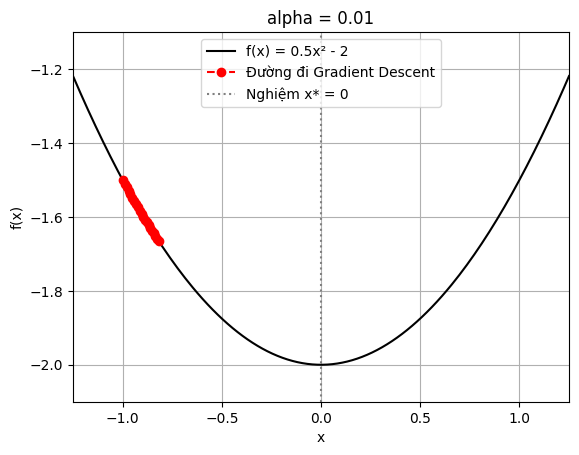

In [2]:
# Thay alpha lần lượt bằng các giá trị trong đề và chạy lại cell này.
alpha = 0.01
result = run_gd_one_minimum(alpha=alpha)

### Chọn alpha và giải thích lựa chọn — lời giải

1. **Các alpha đạt mục tiêu:** $0.5$, $1.0$, $1.5$.
2. **Chọn $1.0$:** cần 1 bước, ít nhất trong các giá trị đã thử.
3. Alpha quá nhỏ có thể làm bước cập nhật ổn định nhưng tiến quá chậm. Với $0.01$, chưa đạt mục tiêu sau 20 bước; với $0.5$, chỉ cần 7 bước.
4. Không. Với $1.5$, khoảng cách giảm một nửa mỗi bước dù đổi phía qua $0$; với $2.0$, khoảng cách giữ nguyên.
5. Không. Tăng từ $0.5$ lên $1.0$ giúp nhanh hơn, nhưng tăng tiếp lên $2.0$ hoặc $3.0$ khiến thuật toán không hội tụ.

### Giải thích bằng công thức

Vì $f'(x)=x$, công thức cập nhật là:
$$x_{t+1}=x_t-\alpha x_t=(1-\alpha)x_t.$$
Từ $x_0=-1$, khoảng cách đến nghiệm sau $t$ bước là:
$$|x_t|=|1-\alpha|^t.$$

| Alpha | Đạt mục tiêu trong 20 bước? | Số bước cần dùng để đạt mục tiêu | Hành vi |
| --- | --- | --- | --- |
| 0.01 | Không | — | Tiến về 0 rất chậm |
| 0.1 | Không | — | Tiến về 0, nhưng chưa đủ gần sau 20 bước |
| 0.5 | Có | 7 | Tiến về 0, không đổi phía |
| 1.0 | Có | 1 | Đến đúng 0 sau một bước |
| 1.5 | Có | 7 | Đổi phía qua 0, khoảng cách giảm dần |
| 2.0 | Không | — | Dao động giữa -1 và 1 |
| 3.0 | Không | — | Đổi phía và ngày càng xa 0 |

Dấu “—” nghĩa là chưa đạt mục tiêu trong giới hạn 20 bước, không có nghĩa là số bước cần dùng bằng 0.


### Bài học sau bài tập

- Chọn alpha cần dựa trên kết quả quan sát và tiêu chí cụ thể, chẳng hạn độ chính xác cần đạt và số bước cho phép.
- Alpha quá nhỏ có thể làm thuật toán chậm; alpha quá lớn có thể gây dao động không giảm hoặc phân kỳ.
- Dao động vẫn có thể hội tụ nếu khoảng cách đến nghiệm giảm dần.
- **Chưa đạt mục tiêu sau 20 bước không đồng nghĩa với không hội tụ.** Có những alpha vẫn đưa điểm cập nhật tiến về nghiệm nhưng cần nhiều bước hơn.
- Alpha phù hợp phụ thuộc vào bài toán. Không nên dùng một con số làm lựa chọn mặc định cho mọi hàm mục tiêu.

Alpha $1.0$ tốt nhất trong ví dụ này nhờ dạng đặc biệt của hàm số: một bước cập nhật đưa mọi vị trí về $0$. Đây không phải quy tắc chọn alpha chung.

## 1.2. Ảnh hưởng của vị trí bắt đầu

Xét hàm số:
$$f(x)=x^6-\frac{3}{16}x^5+\frac{23}{16}x^4-\frac{5}{16}x^3-\frac{79}{16}x^2+1.$$

**Nhiệm vụ:** Giữ nguyên learning rate `alpha = 0.01`, thử các vị trí bắt đầu `[-0.5, 0.0, 0.02, 0.5]` và so sánh kết quả sau cùng **20 bước cập nhật**. Trong các vị trí đã thử, vị trí nào cho giá trị hàm mục tiêu nhỏ nhất sau 20 bước?

Lần lượt thay `x0` trong **cùng một ô code bên dưới** và chạy lại. Hàm hỗ trợ luôn bắt đầu lại tại `x0` đã chọn, chạy đúng 20 bước rồi in vị trí cuối, giá trị hàm mục tiêu và gradient tại vị trí cuối.

Quan sát và so sánh các lần chạy, sau đó chỉ điền đáp án cuối cùng trong phần câu hỏi bên dưới. Có thể chạy lại một vị trí khi cần đối chiếu. Trong bài 1.2, dùng cùng số bước để so sánh các vị trí bắt đầu; không dùng tiêu chí $|x|<0.01$ của bài 1.1 vì nghiệm của hàm này không phải $x=0$.


Vị trí bắt đầu x0: -0.5
Learning rate: 0.01; số bước đã chạy: 20
Vị trí sau 20 bước: -0.88827484
Giá trị hàm mục tiêu khi dừng: -1.18695580
Gradient tại vị trí cuối: 0.10020082


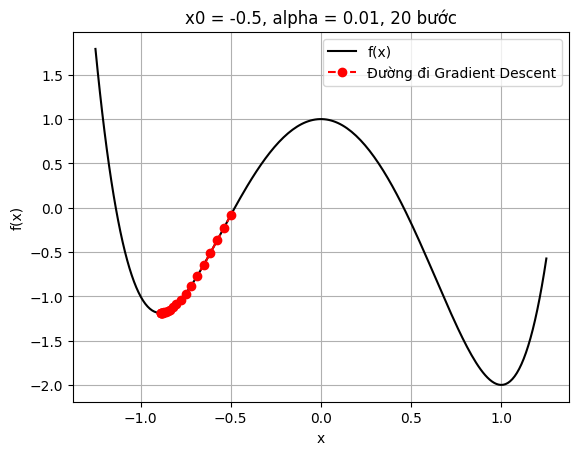

In [3]:
# Lần lượt thay x0 bằng -0.5, 0.0, 0.02, 0.5 rồi chạy lại cell này.
x0 = -0.5
result = run_gd_two_minimums(x0=x0)

### Đáp án và giải thích

| Vị trí bắt đầu | Vị trí sau 20 bước | Giá trị hàm mục tiêu | Gradient tại vị trí cuối |
| --- | --- | --- | --- |
| -0.5 | -0.88827484 | -1.18695580 | 0.10020082 |
| 0.0 | 0.00000000 | 1.00000000 | 0.00000000 |
| 0.02 | 0.13223564 | 0.91337628 | -1.30896862 |
| 0.5 | 0.99751612 | -1.99990242 | -0.07842792 |

1. **Chọn `x0 = 0.5` trong bốn lần thử:** sau 20 bước, giá trị hàm mục tiêu khoảng $-1.99990$, nhỏ nhất trong các kết quả quan sát được. Cần so sánh giá trị hàm mục tiêu, không so sánh độ lớn tọa độ $x$.
2. Hai vị trí $-0.5$ và $0.5$ dẫn thuật toán về hai vùng cực tiểu khác nhau: bên trái và bên phải.
3. Không. Với $x_0=0$, gradient bằng $0$ nên bước cập nhật bằng $0$. Tuy nhiên, các điểm đủ gần $0$ có giá trị hàm nhỏ hơn $f(0)$. Đây là cực đại địa phương; kiểm tra bằng đạo hàm cũng cho $f''(0)=-79/8<0$.
4. Gradient tại $0.02$ khác $0$, nên thuật toán có thể rời vị trí ban đầu. Ban đầu di chuyển chậm vì gradient nhỏ; sau 20 bước mới tới khoảng $0.13224$, chưa đến gần cực tiểu bên phải.
5. Không. Thử bốn vị trí và chạy hữu hạn 20 bước chỉ xác định kết quả tốt nhất trong các lần thử đó. Đây không phải chứng minh đạt cực tiểu toàn cục, cũng không chứng minh các lần chạy đã hội tụ hoàn toàn.


### Bài học sau bài tập

- Giữ nguyên learning rate và số bước để so sánh ảnh hưởng của vị trí bắt đầu.
- Vị trí bắt đầu khác nhau có thể dẫn tới các vùng cực tiểu khác nhau.
- Đánh giá chất lượng kết quả bằng **giá trị hàm mục tiêu**, không phải chỉ bằng tọa độ của nghiệm.
- Gradient bằng $0$ và thuật toán đứng yên không đủ để kết luận đã tìm được cực tiểu.
- Kết quả tốt nhất trong một số lần thử không phải là bằng chứng đạt cực tiểu toàn cục.
- Momentum và adaptive learning rate có thể hỗ trợ tối ưu, nhưng không bảo đảm tìm được cực tiểu toàn cục.


# Bài tập 2: AutoGrad

Mục tiêu của bài tập này là giới thiệu về `torch.autograd` trong việc tính toán gradient. 

`torch.autograd` là một công cụ tự động tính toán gradient băng cách sử dụng backpropagation. Nó giúp cho việc tính toán gradient trở nên dễ dàng hơn mà không cần phải tính công thức gradient cụ thể. 

Công cụ này thường được sử dụng trong việc huấn luyện các mô hình Deep Learning. Ở đây, chúng ta sẽ sử dụng nó để tính toán gradient của một Linear model đơn giản.

In [4]:
import torch
from tqdm import tqdm

## Giới thiệu `torch.tensor` và các phép toán

`torch.tensor` là một đối tượng trong `torch` dùng để lưu trữ dữ liệu và tính toán. Cách khởi tạo một `torch.tensor` như sau:

In [5]:
print("A float tensor: ", torch.tensor(1.0))

A float tensor:  tensor(1.)


In [6]:
print("A tensor of shape (3,): ", torch.tensor([1.0, 2.0, 3.0]))

A tensor of shape (3,):  tensor([1., 2., 3.])


In [7]:
print("A tensor of shape (2, 3): ", torch.tensor([[1.0, 2.0, 3.0], [4.0, 5.0, 6.0]]))

A tensor of shape (2, 3):  tensor([[1., 2., 3.],
        [4., 5., 6.]])


Các phép toán trên `torch.tensor` cũng giống như các phép toán trên `numpy.ndarray`. Ví dụ:

In [8]:
A = torch.tensor([[1.0, 2.0, 3.0], [4.0, 5.0, 6.0]])
x = torch.tensor([1.0, 2.0, 3.0])
b = torch.tensor([1.0, 2.0])
c = torch.tensor([3.0, 4.0])

In [9]:
print("b + c = ", b + c)
print("b - c = ", b - c)
print("b * c = ", b * c)
print("b / c = ", b / c)

b + c =  tensor([4., 6.])
b - c =  tensor([-2., -2.])
b * c =  tensor([3., 8.])
b / c =  tensor([0.3333, 0.5000])


In [10]:
print("Dot product of b and c: ", b @ c)

Dot product of b and c:  tensor(11.)


In [11]:
print("Dot product of A and x: ", A @ x)

Dot product of A and x:  tensor([14., 32.])


## Giới thiệu `torch.autograd`

Xét hàm số $f(x) = ax^2 + bx + c$ với $a, b, c$ là các tham số. Trước nhất bạn hãy tính các đạo hàm riêng của hàm số $f(x)$ theo $a, b, c$.

$$
\begin{align*}
\frac{\partial f}{\partial a} = x^2 \\
\frac{\partial f}{\partial b} = x \\
\frac{\partial f}{\partial c} = 1 \\
\end{align*}
$$

In [12]:
def df_a(x: float) -> float:
    """
        Partial derivative of f with respect to a
    """
    ### START CODE HERE ###
    return x**2
    ### END CODE HERE ###

def df_b(x: float) -> float:
    """
        Partial derivative of f with respect to b
    """
    ### START CODE HERE ###
    return x
    ### END CODE HERE ###

def df_c(x: float) -> float:
    """
        Partial derivative of f with respect to c
    """
    ### START CODE HERE ###
    return 1
    ### END CODE HERE ###

In [13]:
# Run this cell to check your work

a = torch.tensor([1.0], requires_grad=True)
b = torch.tensor([1.0], requires_grad=True)
c = torch.tensor([1.0], requires_grad=True)
f = lambda x: a * x**2 + b * x + c

x_test = [0.0, 1.0, 2.0, 3.0, 4.0]
for x in x_test:
    y = f(x)
    grad_a, grad_b, grad_c = torch.autograd.grad(y, [a, b, c])
    assert grad_a.item() == df_a(x)
    assert grad_b.item() == df_b(x)
    assert grad_c.item() == df_c(x)
print("Success!")

Success!


Khi sử dụng `torch.autograd`, chúng ta cần phải định nghĩa các tham số `a, b, c` có `requires_grad=True` để cho biết rằng chúng ta muốn tính toán gradient của biến này. Sau đó, chúng ta sẽ tính toán hàm số `f` tại `x` và lưu kết quả vào biến `y`. Cuối cùng, ta có thể tính toán gradient của `y` theo các tham số $a, b, c$ bằng cách gọi `torch.autograd.grad(y, [a, b, c])`.

In [14]:
y = f(2.0)
grad_a, grad_b, grad_c = torch.autograd.grad(y, [a, b, c])
print("Gradient of f(2.0) with respect to a:", grad_a.item())
print("Gradient of f(2.0) with respect to b:", grad_b.item())
print("Gradient of f(2.0) with respect to c:", grad_c.item())

Gradient of f(2.0) with respect to a: 4.0
Gradient of f(2.0) with respect to b: 2.0
Gradient of f(2.0) with respect to c: 1.0


Bên trong `pytorch` sẽ xây dựng một computational graph để lưu lại các phép tính được thực hiện trên các biến. Sau đó, `torch.autograd` sẽ tính toán gradient của `y` theo các tham số $a, b, c$ bằng cách sử dụng backpropagation.

![](img/grad_graph.svg)

Từ giới thiệu trên và tự tìm hiểu thêm về `pytorch`, bạn hãy xây dựng lại thuật toán Gradient descent cho mô hình Elastic Net với input trong không gian hai chiều. Elastic Net là một mô hình hồi quy tuyến tính được sử dụng để giải quyết vấn đề overfitting trong mô hình hồi quy tuyến tính. Xét mô hình:

$$
y = w^Tx + b
$$

Trong đó:
- $x \in \mathbb{R}^2$ là input
- $w \in \mathbb{R}^2$ và $b \in \mathbb{R}$ là các tham số của mô hình

Khi này hàm mục tiêu của mô hình Elastic Net là:

$$
L(w, b) = \frac{1}{2N}\sum_{i=1}^N(y_i - (w^Tx_i + b))^2 + \alpha\left(\beta\|w\|_1 + \frac{1 - \beta}{2}\|w\|_2^2\right)
$$

Trong đó:
- $N$ là số lượng mẫu dữ liệu
- $\alpha, \beta$ là các siêu tham số của mô hình

Bạn hãy cài đặt thuật toán Gradient descent dựa trên hướng dẫn trong comment

In [15]:
def l1_norm(x: torch.Tensor) -> torch.Tensor:
    """
        Implement the L1 norm, using torch.sum and torch.abs
    """
    ### START CODE HERE ###
    return torch.sum(torch.abs(x))
    ### END CODE HERE ###
    
def l2_norm_squared(x: torch.Tensor) -> torch.Tensor:
    """
        Implement the L2 norm, using torch.sum and torch.pow
    """
    ### START CODE HERE ###
    return torch.sum(torch.pow(x, 2))
    ### END CODE HERE ###

In [16]:
def gradient_descent_elastic_net(
    X: torch.Tensor,
    y: torch.Tensor,
    num_iters: int,
    lr: float,
    alpha: float = 1.0,
    beta: float = 0.5,
) -> dict:
    """Performs gradient descent on the elastic net loss function.

    Args:
        X: A tensor of shape (N, 2) containing the data.
        y: A tensor of shape (N,) containing the targets.
        num_iters: The number of iterations to perform gradient descent.
        lr: The learning rate.
        alpha, beta: The hyperparameters of the elastic net objective function.

    Returns:
        Dictionary containing the following keys:
            "w": The final value of the weights.
            "b": The final value of the bias.
    """
    assert X.shape[0] == y.shape[0], "X and y must have the same number of rows"
    assert X.shape[1] == 2, "X must have two columns"
    assert len(y.shape) == 1, "y must be a vector"
    N = X.shape[0]    
    
    # Initialize the weights and bias, and set requires_grad=True
    ### START CODE HERE ###
    w = torch.rand(2, 1, requires_grad=True)
    b = torch.rand(1, requires_grad=True)
    ### END CODE HERE ###
    
    
    pb = tqdm(range(num_iters))
    # Run gradient descent
    for epoch in pb:
        # Calculate the predictions
        ### START CODE HERE ###
        y_pred = (X @ w + b).squeeze()
        ### END CODE HERE ###
        
        # Compute the value of the objective function
        ### START CODE HERE ###
        L = 1/(2*N) * l2_norm_squared(y_pred - y) + alpha * (beta * l1_norm(w) + ((1 - beta) / 2) * l2_norm_squared(w))
        ### END CODE HERE ###
        
        # Compute the gradients
        ### START CODE HERE ###
        grad_w, grad_b = torch.autograd.grad(L, [w, b])
        ### END CODE HERE ###
        
        # Update the weights and bias
        ### START CODE HERE ###
        with torch.no_grad():
            w -= lr * grad_w
            b -= lr * grad_b
        ### END CODE HERE ###
        
        # Print verbose output (optional)
        pb.set_description(f"Loss: {L.item():.4f}")

    return {"w": w.squeeze().tolist(), "b": b.item()}

In [17]:
# You can tune this variable to see the effect of different regularization terms
alpha = 0.5

In [18]:
# Run this cell to check your work
num_samples = 100

w = torch.tensor([[1.0], [2.0]])
b = torch.tensor([3.0])
X = torch.randn(num_samples, 2)
y = X @ w + b + 0.01*torch.randn(num_samples, 1)
y = y.squeeze()

gradient_descent_elastic_net(
    X=X,
    y=y,
    num_iters=250,
    lr=0.1,
    alpha=alpha,
    beta=0.5,
)

  0%|          | 0/250 [00:00<?, ?it/s]

Loss: 5.8678:   0%|          | 0/250 [00:00<?, ?it/s]

Loss: 4.8213:   0%|          | 0/250 [00:00<?, ?it/s]

Loss: 4.0046:   0%|          | 0/250 [00:00<?, ?it/s]

Loss: 3.3662:   0%|          | 0/250 [00:00<?, ?it/s]

Loss: 2.8667:   0%|          | 0/250 [00:00<?, ?it/s]

... (244 outputs left out)

Loss: 1.0081:  79%|███████▉  | 198/250 [00:00<00:00, 1977.58it/s]

Loss: 1.0081:  79%|███████▉  | 198/250 [00:00<00:00, 1977.58it/s]

Loss: 1.0081: 100%|██████████| 250/250 [00:00<00:00, 1982.28it/s]

{'w': [0.5492205023765564, 1.3230233192443848], 'b': 3.1419730186462402}

# Bài tập 3:  Cài đặt thuật toán Gradient Descent with Momentum


Trong bài tập này, chúng ta sẽ cài đặt thuật toán Gradient Descent with Momentum để dự đoán giá cổ phiếu của Tesla.  

## Tổng quan về dữ liệu

Bạn được cung cấp một bộ dữ liệu ở dạng file `.csv` chứa thông tin cổ phiếu của Tesla. Thông tin về các trường dữ liệu như sau:

📈📈 **Thông tin về dữ liệu (tesla_stock.csv)** 📈📈
- Open: Giá mở cửa của cổ phiếu 
- High: Giá cao nhất của ngày hôm đó 
- Low: Giá thấp nhất của ngày hôm đó 
- Close: Giá đóng của của ngày hôm đó 
- Volume: Lượng cổ phiếu đã giao dịch trong cả ngày hôm đó

Nhiệm vụ của bạn là dự đoán giá đóng cửa (close) dựa vào tất cả các đặc trưng còn lại. 

In [19]:
from sklearn.preprocessing import MinMaxScaler
from sklearn.model_selection import train_test_split
import pandas as pd
import numpy as np
stock_path = 'tesla_stock.csv'
data = pd.read_csv(stock_path)

In [20]:
data.head()

,Open,High,Low,Close,Volume
0,19.000000,25.00,17.540001,23.889999,18766300
1,25.790001,30.42,23.299999,23.830000,17187100
2,25.000000,25.92,20.270000,21.959999,8218800
3,23.000000,23.10,18.709999,19.200001,5139800
4,20.000000,20.00,15.830000,16.110001,6866900


In [21]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2416 entries, 0 to 2415
Data columns (total 5 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   Open    2416 non-null   float64
 1   High    2416 non-null   float64
 2   Low     2416 non-null   float64
 3   Close   2416 non-null   float64
 4   Volume  2416 non-null   int64  
dtypes: float64(4), int64(1)
memory usage: 94.5 KB


## Cài đặt thuật toán Gradient Descent with Momentum

### Thuật toán Momentum

**Thuật toán Momentum** là một biến thể của Gradient Descent, được sử dụng để tăng tốc độ hội tụ của mô hình học máy bằng cách sử dụng momentum. Thay vì chỉ dựa trên gradient của hàm mất mát tại một điểm cụ thể, thuật toán này sử dụng thông tin về hướng di chuyển trước đó để đưa ra cập nhật mới cho tham số.

#### Ý nghĩa của việc áp dụng thuật toán Momentum:
1. **Giảm dao động:** Khi gradient thay đổi mạnh giữa các bước, động lượng giúp giảm sự dao động không cần thiết và tập trung vào hướng đúng để tìm điểm tối ưu.
2. **Tăng tốc:** Giúp mô hình hội tụ nhanh hơn, đặc biệt là trong các vùng có độ cong cao hoặc khi gradient có sự thay đổi nhỏ và nhất quán.
3. **Giảm hiệu ứng "bẫy" tại điểm yên ngựa:** Momentum giúp tránh trường hợp mô hình bị mắc kẹt tại những điểm yên ngựa, nơi gradient rất nhỏ và mô hình tiến triển chậm.

#### Công thức của thuật toán Momentum:
Giả sử:
- $ W $ là các trọng số của mô hình.
- $ b $ là hệ số bias.
- $ \alpha $ là tốc độ học (learning rate).
- $ \beta $ là hệ số momentum (thường chọn $ 0.9 $).
- $ V_{dW} $ và $ V_{db} $ là vận tốc (velocity) của gradient trọng số và bias.

Công thức cập nhật các trọng số và bias như sau:

1. **Cập nhật vận tốc:**
   $$
   V_{dW} = \beta V_{dW} + (1 - \beta) \nabla W
   $$
   $$
   V_{db} = \beta V_{db} + (1 - \beta) \nabla b
   $$
   
   Trong đó $ \nabla W $ và $ \nabla b $ là gradient của trọng số và bias tương ứng.

2. **Cập nhật tham số:**
   $$
   W = W - \alpha V_{dW}
   $$
   $$
   b = b - \alpha V_{db}
   $$

Như vậy, việc áp dụng **Momentum** giúp mô hình học nhanh hơn và ổn định hơn trong quá trình tối ưu hóa, đặc biệt là trong các bài toán với dữ liệu lớn và nhiều nhiễu.

**Chuẩn hóa dữ liệu:** Scaler chỉ được học các giá trị min/max từ tập train. Tập test được biến đổi bằng scaler đã fit, không được dùng để xác định cách chuẩn hóa. Giá trị test sau biến đổi có thể nằm ngoài khoảng `[0, 1]`; đây không phải lỗi.

Features và target dùng hai scaler riêng. Bảng so sánh dự đoán ở cuối bài sử dụng giá trị target đã chuẩn hóa, không phải giá cổ phiếu ở đơn vị gốc.


In [22]:
# Step 1: Tách features và target trên dữ liệu gốc.
X = data[['Open', 'High', 'Low', 'Volume']].values
y = data['Close'].values

# Step 2: Chia train/test trước khi chuẩn hóa.
X_train_raw, X_test_raw, y_train_raw, y_test_raw = train_test_split(
    X, y, test_size=0.2, random_state=0
)

# Fit scaler chỉ trên train; dùng transform cho test.
X_scaler = MinMaxScaler()
X_train = X_scaler.fit_transform(X_train_raw)
X_test = X_scaler.transform(X_test_raw)

y_scaler = MinMaxScaler()
y_train = y_scaler.fit_transform(y_train_raw.reshape(-1, 1)).ravel()
y_test = y_scaler.transform(y_test_raw.reshape(-1, 1)).ravel()

# Step 3: Định nghĩa hàm khởi tạo tham số.
def initialize_parameters(n_features):
    """
    Initialize weights and bias to zeros.

    Parameters:
    - n_features: Number of features

    Returns:
    - W: Weights vector
    - b: Bias term
    """
    ### START CODE HERE ###
    W = np.zeros(n_features)
    b = 0
    ### END CODE HERE ### 
    
    return W, b

In [23]:
# Test the initialize_parameters function
W_test, b_test = initialize_parameters(4)
assert W_test.shape == (4,), f"Expected W shape (4,), got {W_test.shape}"
assert np.all(W_test == 0), "W should be initialized to zeros"
assert b_test == 0, f"Expected b to be 0, got {b_test}"
print("initialize_parameters function passed all tests!")

initialize_parameters function passed all tests!


In [24]:
# Step 4: Cài đặt thuật toán Gradient Descent with Momentum 
def gradient_descent_momentum(X, y, alpha=0.01, beta=0.9, iterations=1000):
    """
    Perform gradient descent with momentum to optimize weights and bias.

    Parameters:
    - X: Feature matrix
    - y: Target vector
    - alpha: Learning rate
    - beta: Momentum factor
    - iterations: Number of iterations

    Returns:
    - W: Optimized weights
    - b: Optimized bias
    """
    n_samples, n_features = X.shape
    W, b = initialize_parameters(n_features)
    
    # Initialize velocity terms for momentum
    V_dW = np.zeros(n_features)
    V_db = 0
    
    for i in range(iterations):
        # Step 4.1: Tính giá trị dự đoán
        ### START CODE HERE ###
        y_pred = np.dot(X, W) + b
        ### END CODE HERE ###
        
        # Step 4.2: Tính gradients 
        ### START CODE HERE ###
        dW = (1 / n_samples) * np.dot(X.T, (y_pred - y))
        db = (1 / n_samples) * np.sum(y_pred - y)
        ### END CODE HERE ###
        
        # Step 4.3: Cập nhật velocities cho momentum
        ### START CODE HERE ###
        V_dW = beta * V_dW + (1 - beta) * dW
        V_db = beta * V_db + (1 - beta) * db
        ### END CODE HERE ###
        
        # Step 4.4: Cập nhật weights và bias
        ### START CODE HERE ###
        W -= alpha * V_dW
        b -= alpha * V_db
        ### END CODE HERE ###
        
        # In ra giá trị cost sau mỗi 100 iterations
        if i % 100 == 0:
            cost = (1 / (2 * n_samples)) * np.sum((y_pred - y) ** 2)
            print(f"Iteration {i}: Cost {cost}")
    
    return W, b

# Step 5: Huấn luyện mô hình với dữ liệu đã có
W, b = gradient_descent_momentum(X_train, y_train, alpha=0.01, beta=0.9, iterations=1000)

# Step 6: Output the optimized weights and bias
print("Optimized weights:", W)
print("Optimized bias:", b)

Iteration 0: Cost 0.037317983895344325
Iteration 100: Cost 0.009613719860256921
Iteration 200: Cost 0.006316819855077659
Iteration 300: Cost 0.005308725304161686
Iteration 400: Cost 0.0045543814315196236
Iteration 500: Cost 0.0039137338057896945
Iteration 600: Cost 0.0033643230564773044
Iteration 700: Cost 0.002892820766481427
Iteration 800: Cost 0.0024881511026049867
Iteration 900: Cost 0.002140831622615459
Optimized weights: [0.18913725 0.16463676 0.18614133 0.05622548]
Optimized bias: 0.09079581067789998


In [25]:
# Hàm dự đoán giá đóng cửa
def predict(X, W, b):
    """
    Make predictions using the linear model.

    Parameters:
    - X: Feature matrix
    - W: Weights vector
    - b: Bias term

    Returns:
    - y_pred: Predicted values
    """
    ### START CODE HERE ###
    return np.dot(X, W) + b
    ### END CODE HERE ###

# Dự đoán giá đóng cửa của tập test
y_pred = predict(X_test, W, b)

# So sánh target thực tế và dự đoán trong đơn vị đã chuẩn hóa
comparison = pd.DataFrame({'Actual (scaled)': y_test, 'Predicted (scaled)': y_pred})
comparison

,Actual (scaled),Predicted (scaled)
0,0.251152,0.248228
1,0.016331,0.101588
2,0.010743,0.098667
3,0.391822,0.352833
4,0.241350,0.237559
...,...,...
479,0.225360,0.232208
480,0.439833,0.365246
481,0.014983,0.100324
482,0.222520,0.227199
